Logistic Regression Accuracy: 0.8654708520179372
Perceptron Accuracy: 0.9757847533632287

Convergence Speed
Logistic Regression:
Converged in 1000 epochs
Perceptron:
Converged in 6 epochs

Perceptron converged faster

Number of TF-IDF Features: 7735


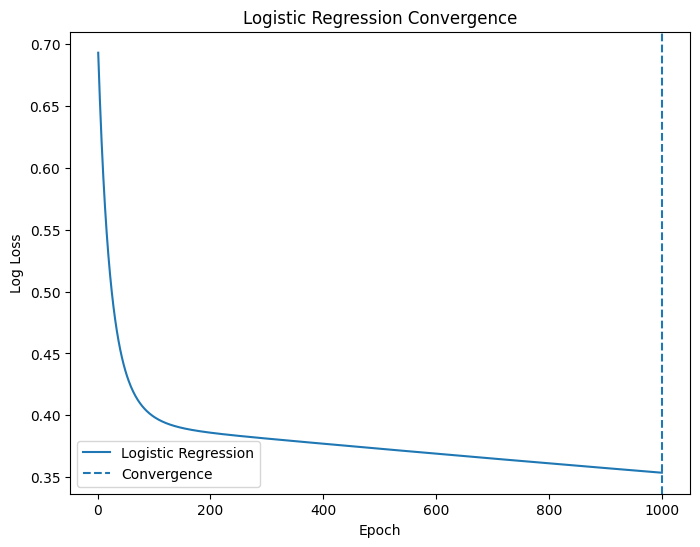

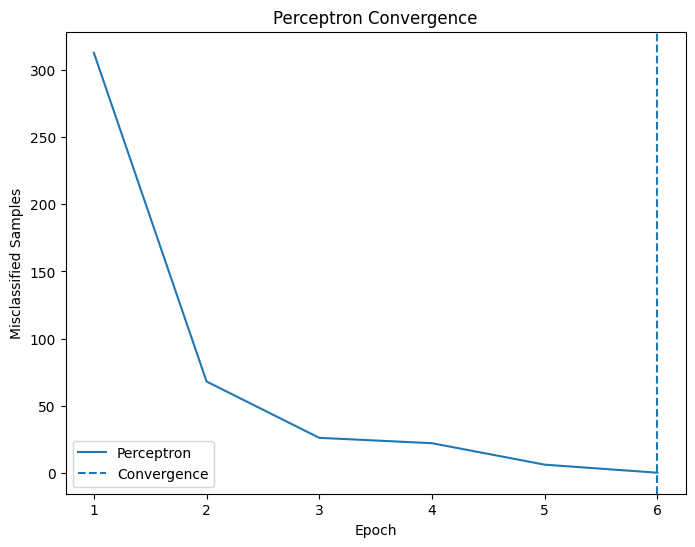

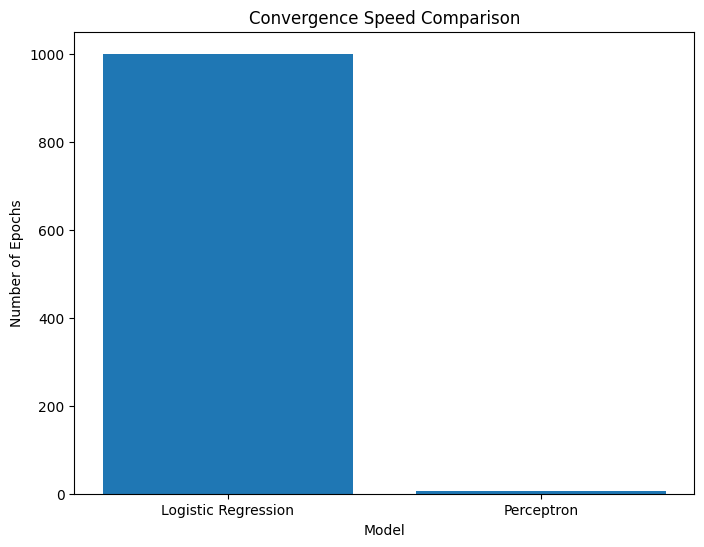

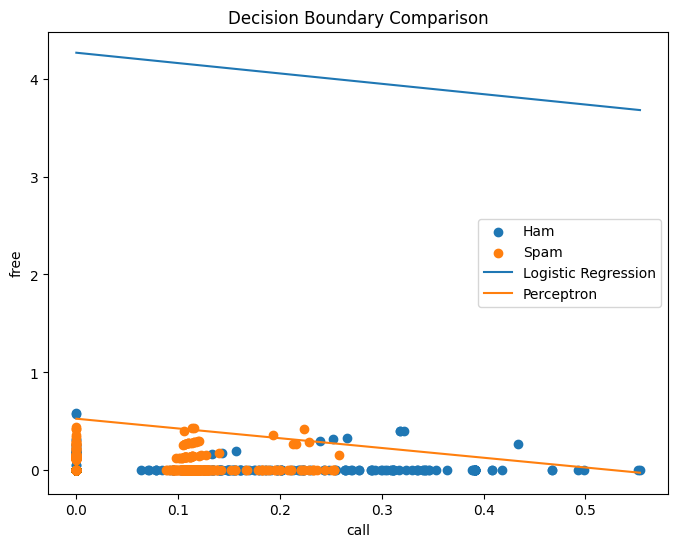

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
df=pd.read_csv("spam.csv",encoding="latin-1")
df=df[["v1","v2"]]
df.columns=["label","message"]
df["label"]=df["label"].map({"ham":0,"spam":1})
X_train_text,X_test_text,y_train,y_test=train_test_split(
    df["message"],
    df["label"].values,
    test_size=0.2,
    random_state=42
)
vectorizer=TfidfVectorizer()
X_train=vectorizer.fit_transform(X_train_text).toarray()
X_test=vectorizer.transform(X_test_text).toarray()
def sigmoid(z):
    return 1/(1+np.exp(-np.clip(z,-500,500)))
def logistic_regression(X,y,learning_rate=0.1,epochs=1000,tolerance=1e-6,patience=5):
    weights=np.zeros(X.shape[1])
    bias=0
    losses=[]
    stable_count=0
    convergence_epoch=None
    for epoch in range(epochs):
        z=np.dot(X,weights)+bias
        y_pred=sigmoid(z)

        loss=-np.mean(
            y*np.log(y_pred+1e-15)+(1-y)*np.log(1-y_pred+1e-15)
        )
        losses.append(loss)
        dw=np.dot(X.T,y_pred-y)/len(y)
        db=np.mean(y_pred-y)
        weights-=learning_rate*dw
        bias-=learning_rate*db
        if epoch>0:
            improvement=abs(losses[-2]-losses[-1])
            if improvement<tolerance:
                stable_count+=1
            else:
                stable_count=0
            if stable_count>=patience:
                convergence_epoch=epoch+1
                break
    if convergence_epoch is None:
        convergence_epoch=epochs
    return weights,bias,losses,convergence_epoch
def logistic_predict(X,weights,bias):
    probability=sigmoid(np.dot(X,weights)+bias)
    return (probability>=0.5).astype(int)
def perceptron(X,y,learning_rate=0.01,epochs=1000):
    weights=np.zeros(X.shape[1])
    bias=0
    errors=[]
    convergence_epoch=None
    for epoch in range(epochs):
        error_count=0
        for i in range(len(X)):
            z=np.dot(X[i],weights)+bias
            prediction=1 if z>=0 else 0
            error=y[i]-prediction
            if error!=0:
                weights+=learning_rate*error*X[i]
                bias+=learning_rate*error
                error_count+=1
        errors.append(error_count)
        if error_count==0:
            convergence_epoch=epoch+1
            break
    return weights,bias,errors,convergence_epoch
def perceptron_predict(X,weights,bias):
    predictions=[]
    for i in range(len(X)):
        z=np.dot(X[i],weights)+bias
        predictions.append(1 if z>=0 else 0)
    return np.array(predictions)
lr_weights,lr_bias,lr_losses,lr_convergence=logistic_regression(
    X_train,y_train
)
lr_pred=logistic_predict(
    X_test,lr_weights,lr_bias
)
lr_accuracy=accuracy_score(
    y_test,lr_pred
)
p_weights,p_bias,p_errors,p_convergence=perceptron(
    X_train,y_train
)
p_pred=perceptron_predict(
    X_test,p_weights,p_bias
)
p_accuracy=accuracy_score(
    y_test,p_pred
)
print("Logistic Regression Accuracy:",lr_accuracy)
print("Perceptron Accuracy:",p_accuracy)
print("\nConvergence Speed")
print("Logistic Regression:")
print("Converged in",lr_convergence,"epochs")
if p_convergence is not None:
    print("Perceptron:")
    print("Converged in",p_convergence,"epochs")
else:
    print("Perceptron:")
    print("Did not converge within",len(p_errors),"epochs")
if p_convergence is not None:
    if lr_convergence<p_convergence:
        print("\nLogistic Regression converged faster")
    elif p_convergence<lr_convergence:
        print("\nPerceptron converged faster")
    else:
        print("\nBoth converged at the same speed")
else:
    print("\nLogistic Regression converged faster")
print("\nNumber of TF-IDF Features:",X_train.shape[1])
plt.figure(figsize=(8,6))
plt.plot(
    range(1,len(lr_losses)+1),
    lr_losses,
    label="Logistic Regression"
)
plt.axvline(
    lr_convergence,
    linestyle="--",
    label="Convergence"
)
plt.xlabel("Epoch")
plt.ylabel("Log Loss")
plt.title("Logistic Regression Convergence")
plt.legend()
plt.show()

plt.figure(figsize=(8,6))
plt.plot(
    range(1,len(p_errors)+1),
    p_errors,
    label="Perceptron"
)
if p_convergence is not None:
    plt.axvline(
        p_convergence,
        linestyle="--",
        label="Convergence"
    )
plt.xlabel("Epoch")
plt.ylabel("Misclassified Samples")
plt.title("Perceptron Convergence")
plt.legend()
plt.show()
if p_convergence is not None:
    models=["Logistic Regression","Perceptron"]
    convergence_epochs=[lr_convergence,p_convergence]
    plt.figure(figsize=(8,6))
    plt.bar(models,convergence_epochs)
    plt.ylabel("Number of Epochs")
    plt.xlabel("Model")
    plt.title("Convergence Speed Comparison")
    plt.show()
feature_names=vectorizer.get_feature_names_out()
feature_1=np.argmax(np.abs(lr_weights))
feature_2=np.argsort(np.abs(lr_weights))[-2]
X_visual=X_train[:,[feature_1,feature_2]]
lr_w1=lr_weights[feature_1]
lr_w2=lr_weights[feature_2]
p_w1=p_weights[feature_1]
p_w2=p_weights[feature_2]
x=np.linspace(
    X_visual[:,0].min(),
    X_visual[:,0].max(),
    100
)
plt.figure(figsize=(8,6))
plt.scatter(
    X_visual[y_train==0,0],
    X_visual[y_train==0,1],
    label="Ham"
)
plt.scatter(
    X_visual[y_train==1,0],
    X_visual[y_train==1,1],
    label="Spam"
)
if abs(lr_w2)>1e-12:
    lr_boundary=-(lr_w1*x+lr_bias)/lr_w2
    plt.plot(
        x,
        lr_boundary,
        label="Logistic Regression"
    )
if abs(p_w2)>1e-12:
    p_boundary=-(p_w1*x+p_bias)/p_w2
    plt.plot(
        x,
        p_boundary,
        label="Perceptron"
    )
plt.xlabel(feature_names[feature_1])
plt.ylabel(feature_names[feature_2])
plt.title("Decision Boundary Comparison")
plt.legend()
plt.show()